# Análisis de reclamos ciudadanos — Ciudad de Buenos Aires (2024–2026)

## 1. Contexto

La Ciudad registra en el **Sistema Único de Atención Ciudadana (SUACI) / BA Colaborativa** los contactos de
vecinos y vecinas: reclamos, denuncias, quejas, solicitudes y consultas que entran por la línea 147,
el chatbot Boti, la web, la app y las sedes comunales.

**Objetivo:** entender cuánta demanda entra, dónde se concentra, qué proporción se cierra y si hay patrones
en el tiempo, para orientar dónde poner recursos.

**Datos:** [Buenos Aires Data](https://data.buenosaires.gob.ar/dataset/sistema-unico-atencion-ciudadana) (licencia CC-BY-2.5-AR),
del 01/01/2024 al 15/10/2026. Se descargan con `src/download.py` y se limpian con `src/clean.py`.

**Preguntas:**
1. ¿Cuántos reclamos entran por mes y cómo evoluciona el volumen?
2. ¿Qué categorías y comunas concentran más reclamos?
3. ¿Qué tasa de cierre (% cerrado) tiene cada categoría?
4. ¿Qué tasa de cierre tiene cada comuna?
5. ¿Hay estacionalidad por día de la semana o por mes?

> El dataset no publica la fecha de cierre, solo el estado (Abierto/Cerrado). Por eso no se mide el tiempo
> de resolución sino la **tasa de cierre**.

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from build_db import load_queries  # noqa: E402
from clean import PROCESSED_DIR  # noqa: E402

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Paleta: una serie en azul, naranja solo para resaltar, texto en grises
AZUL, NARANJA, GRIS, TEXTO, TEXTO_2 = "#2a78d6", "#eb6834", "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": GRIS, "axes.labelcolor": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO,
})


def miles(x, _=None):
    """Formato argentino: 1.234.567"""
    return f"{x:,.0f}".replace(",", ".")


def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")


# Vista sobre el parquet limpio (no carga todo en memoria) y consultas de sql/kpis.sql
con = duckdb.connect()
parquet = (PROCESSED_DIR / "reclamos_clean.parquet").as_posix()
con.sql(f"CREATE VIEW reclamos AS SELECT * FROM read_parquet('{parquet}')")
QUERIES = load_queries()


def consulta(nombre):
    return con.sql(QUERIES[nombre]).df()


total = con.sql("SELECT count(*) FROM reclamos").fetchall()[0][0]
print(f"Reclamos analizados: {miles(total)}")

Reclamos analizados: 3.361.232


## 2. Calidad de datos

Resumen de lo que hizo `src/clean.py` (el script guarda estos conteos en `data/processed/calidad.json`):

In [2]:
calidad = json.loads((PROCESSED_DIR / "calidad.json").read_text(encoding="utf-8"))
pd.Series(calidad, name="filas").map(miles).to_frame()

,filas
filas_crudas,3.363.595
descartados_invalidos,1
duplicados_nro_solicitud,0
duplicados_misma_carga,2.362
comunas_fuera_de_rango,0
filas_finales,3.361.232


In [3]:
# Porcentaje de nulos por año en las columnas con faltantes
con.sql("""
    SELECT anio,
           round(100 * avg(CASE WHEN comuna IS NULL THEN 1 ELSE 0 END), 1) AS comuna_nula_pct,
           round(100 * avg(CASE WHEN barrio IS NULL THEN 1 ELSE 0 END), 1) AS barrio_nulo_pct,
           round(100 * avg(CASE WHEN genero IS NULL THEN 1 ELSE 0 END), 1) AS genero_nulo_pct
    FROM reclamos GROUP BY anio ORDER BY anio
""").df()

,anio,comuna_nula_pct,barrio_nulo_pct,genero_nulo_pct
0,2024,8.7,8.7,0.0
1,2025,33.2,33.4,9.0
2,2026,27.6,27.8,6.7


**Hallazgos de calidad:**

- **Formatos distintos por año:** separador (`;` / `,`), fecha (`d/m/aaaa` / ISO), hora (24 h / am-pm) y nombre de las
  columnas de coordenadas. Se unificaron en la limpieza.
- **Error de origen en la hora (2024 y 2025):** el campo de minutos contiene el mes en el 100 % de las filas.
  Solo se usa la hora en punto.
- **Cargas duplicadas:** registros con distinto número pero misma dirección, trámite y momento. Se quitaron.
- **Ubicación incompleta:** una de cada cuatro filas no tiene comuna (trámites sin dirección, como consultas y
  turnos), y el faltante sube de 9 % en 2024 a 33 % en 2025. Los análisis por comuna usan solo filas con ubicación.
- **No hay fecha de cierre:** la tasa de cierre de 2026 es más baja en parte porque son reclamos recientes.

## 3. Volumen y concentración

### P1. ¿Cuántos reclamos entran por mes?

In [4]:
p1 = consulta("p1_evolucion_mensual")
p1.tail(14)

,mes,reclamos,var_mensual_pct,var_interanual_pct,estado_mes
20,2025-09,103314,20.2,53.7,completo
21,2025-10,162042,56.8,145.8,completo
22,2025-11,159043,-1.9,141.2,completo
23,2025-12,153423,-3.5,133.9,completo
24,2026-01,137267,-10.5,110.2,completo
25,2026-02,130818,-4.7,60.4,completo
26,2026-03,152510,16.6,-33.3,completo
27,2026-04,133656,-12.4,-24.4,completo
28,2026-05,102109,-23.6,20.4,completo
29,2026-06,101674,-0.4,36.3,completo


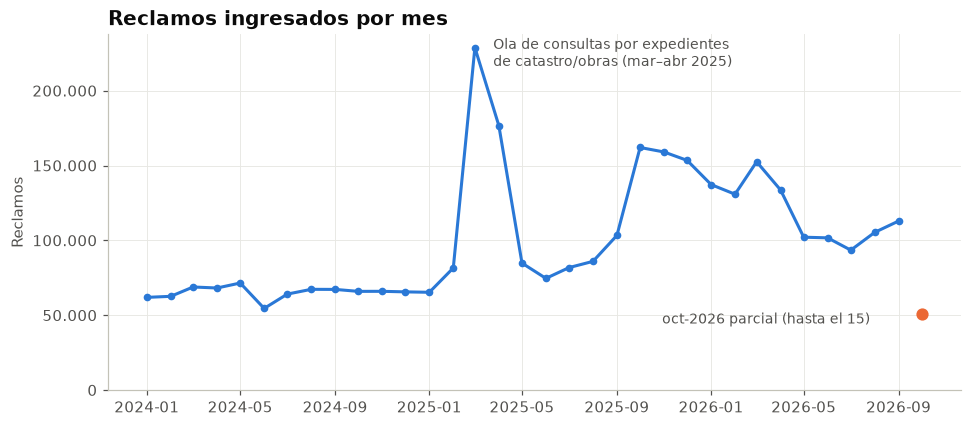

In [5]:
p1["fecha"] = pd.to_datetime(p1["mes"])
completos = p1[p1["estado_mes"] == "completo"]
parcial = p1[p1["estado_mes"] == "parcial"]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(completos["fecha"], completos["reclamos"], color=AZUL, linewidth=2, marker="o", markersize=4)
ax.plot(parcial["fecha"], parcial["reclamos"], color=NARANJA, marker="o", markersize=7, linestyle="none")
ax.annotate("oct-2026 parcial (hasta el 15)", (parcial["fecha"].iloc[0], parcial["reclamos"].iloc[0]),
            xytext=(-170, -6), textcoords="offset points", color=TEXTO_2, fontsize=9)
pico = completos.loc[completos["reclamos"].idxmax()]
ax.annotate("Ola de consultas por expedientes\nde catastro/obras (mar–abr 2025)", (pico["fecha"], pico["reclamos"]),
            xytext=(12, -12), textcoords="offset points", color=TEXTO_2, fontsize=9)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(miles))
ax.set_ylim(0, None)
ax.set_title("Reclamos ingresados por mes")
ax.set_xlabel("")
ax.set_ylabel("Reclamos")
guardar(fig, "01_evolucion_mensual")
plt.show()

El volumen fue estable en 2024 (~65 mil por mes) y cambió de escala desde octubre de 2025. Veamos qué
categorías explican el salto:

In [6]:
cambio = con.sql("""
    SELECT categoria,
           round(count(*) FILTER (WHERE fecha_ingreso BETWEEN '2024-10-01' AND '2025-09-30') / 12) AS promedio_mensual_antes,
           round(count(*) FILTER (WHERE fecha_ingreso BETWEEN '2025-10-01' AND '2026-09-30') / 12) AS promedio_mensual_despues
    FROM reclamos GROUP BY categoria
""").df()
cambio["diferencia"] = cambio["promedio_mensual_despues"] - cambio["promedio_mensual_antes"]
cambio.sort_values("diferencia", ascending=False).head(5)

,categoria,promedio_mensual_antes,promedio_mensual_despues,diferencia
46,PLATAFORMA BA COLABORATIVA,0.0,18050.0,18050.0
47,HIGIENE,30491.0,46548.0,16057.0
35,EDUCACIÓN,2120.0,5466.0,3346.0
17,PERSONAS O FAMILIAS EN SITUACIÓN DE CALLE,111.0,3024.0,2913.0
21,MDA,4107.0,6972.0,2865.0


### P2. ¿Qué categorías y comunas concentran más reclamos?

In [7]:
p2a = consulta("p2a_top_categorias")
p2a

,categoria,reclamos,pct_total,pct_acumulado
0,HIGIENE,1159408,34.5,34.5
1,DENUNCIA VIAL,534740,15.9,50.4
2,DESARROLLO URBANO,312325,9.3,59.7
3,PLATAFORMA BA COLABORATIVA,222495,6.6,66.3
4,ARBOLADO,172542,5.1,71.4
5,MDA,163526,4.9,76.3
6,VEREDAS,100084,3.0,79.3
7,EDUCACIÓN,94770,2.8,82.1
8,ALUMBRADO,90119,2.7,84.8
9,SALUD,88351,2.6,87.4


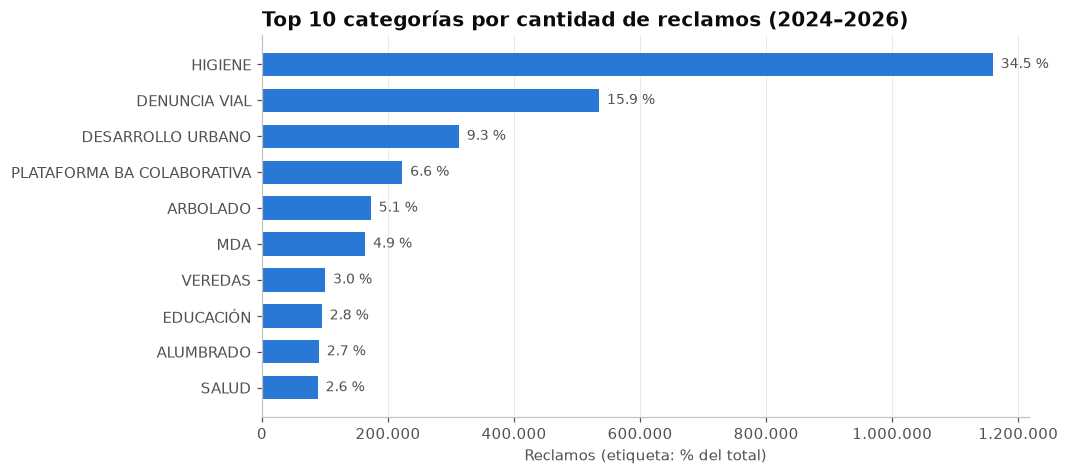

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
datos = p2a.sort_values("reclamos")
ax.barh(datos["categoria"], datos["reclamos"], color=AZUL, height=0.65)
for y, (valor, pct) in enumerate(zip(datos["reclamos"], datos["pct_total"])):
    ax.text(valor, y, f"  {pct:.1f} %", va="center", color=TEXTO_2, fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(miles))
ax.grid(axis="y", visible=False)
ax.set_title("Top 10 categorías por cantidad de reclamos (2024–2026)")
ax.set_xlabel("Reclamos (etiqueta: % del total)")
guardar(fig, "02_top_categorias")
plt.show()

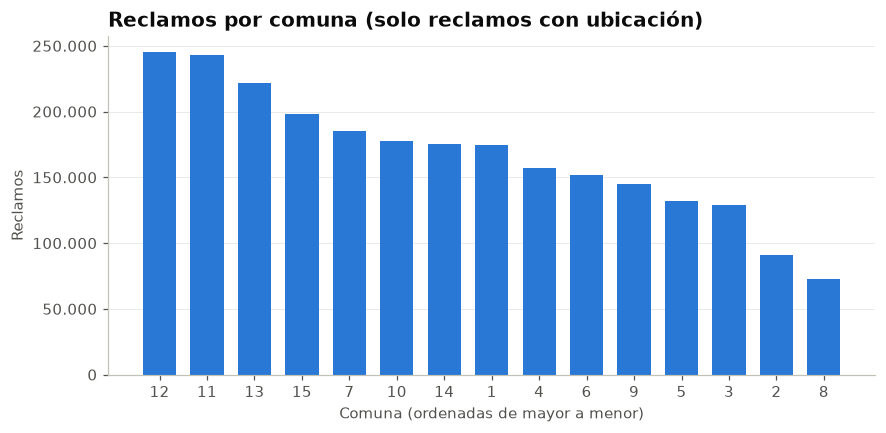

,comuna,reclamos,pct_con_ubicacion,ranking
0,12,245332,9.8,1
1,11,242939,9.7,2
2,13,221425,8.9,3
3,15,197934,7.9,4
4,7,185576,7.4,5


In [9]:
p2b = consulta("p2b_reclamos_por_comuna")
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(p2b["comuna"].astype(str), p2b["reclamos"], color=AZUL, width=0.7)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(miles))
ax.grid(axis="x", visible=False)
ax.set_title("Reclamos por comuna (solo reclamos con ubicación)")
ax.set_xlabel("Comuna (ordenadas de mayor a menor)")
ax.set_ylabel("Reclamos")
guardar(fig, "03_reclamos_por_comuna")
plt.show()
p2b.head(5)

## 4. Tasa de cierre

### P3. ¿Qué tasa de cierre tiene cada categoría?

In [10]:
p3 = consulta("p3_tasa_cierre_categoria")
p3

,categoria,reclamos,tasa_cierre_pct,tasa_cierre_2024_2025_pct,abiertos
0,VEREDAS,100084,44.6,45.3,55423.0
1,ESPACIOS VERDES,6215,45.2,47.9,3404.0
2,ECOPARQUE,9570,55.2,52.3,4283.0
3,LIBRO DE QUEJAS,12823,56.6,62.7,5571.0
4,ACCESO A LA INFORMACIÓN,26375,57.2,61.7,11293.0
5,ESPACIO PÚBLICO,15797,59.2,63.6,6450.0
6,SUBTE,8721,61.4,51.7,3363.0
7,SALUD,88351,63.7,60.0,32102.0
8,MEPHU FISCALIZACIÓN,5815,69.8,66.9,1757.0
9,RESOLUCIONES URBANAS,46625,72.7,76.4,12741.0


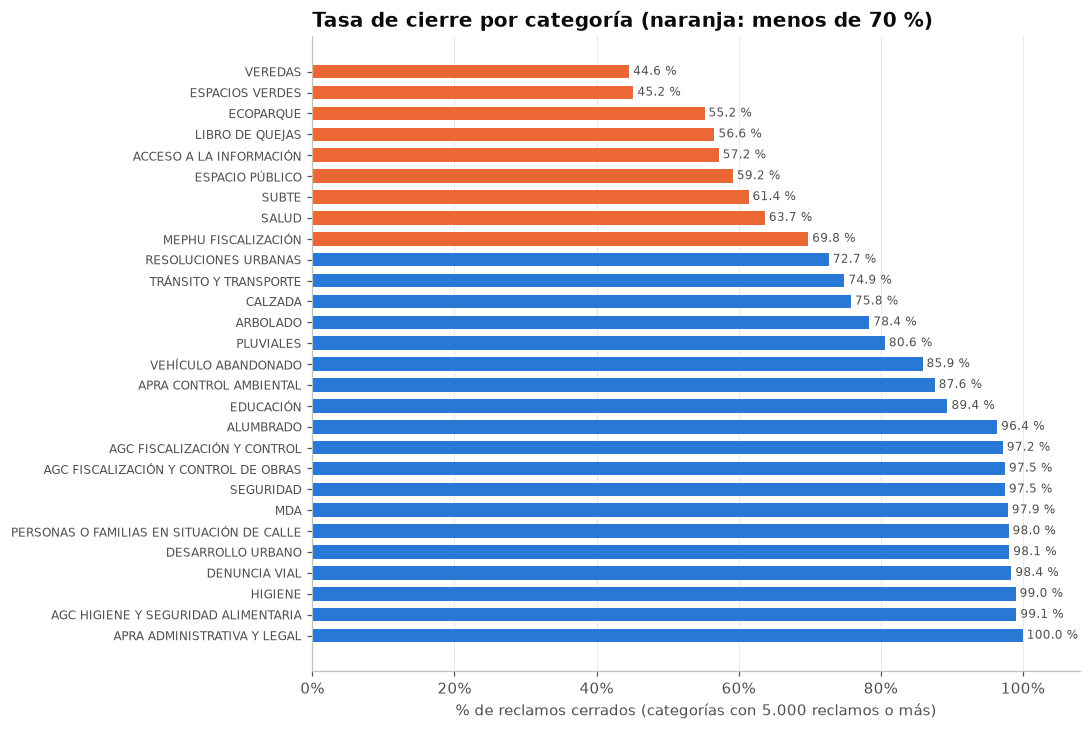

In [11]:
UMBRAL = 70  # categorías por debajo de este % se resaltan
fig, ax = plt.subplots(figsize=(9, 7.5))
datos = p3.sort_values("tasa_cierre_pct", ascending=False)
colores = [NARANJA if t < UMBRAL else AZUL for t in datos["tasa_cierre_pct"]]
ax.barh(datos["categoria"], datos["tasa_cierre_pct"], color=colores, height=0.65)
for y, t in enumerate(datos["tasa_cierre_pct"]):
    ax.text(t, y, f" {t:.1f} %", va="center", color=TEXTO_2, fontsize=8)
ax.set_xlim(0, 108)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
ax.set_title(f"Tasa de cierre por categoría (naranja: menos de {UMBRAL} %)")
ax.set_xlabel("% de reclamos cerrados (categorías con 5.000 reclamos o más)")
guardar(fig, "04_tasa_cierre_categoria")
plt.show()

### P4. ¿Qué tasa de cierre tiene cada comuna?

In [12]:
p4 = consulta("p4_tasa_cierre_comuna")
p4

,comuna,reclamos,tasa_cierre_pct,dif_vs_promedio_pp,comparacion
0,7,185576,88.7,-3.6,por debajo
1,4,157263,90.3,-2.1,por debajo
2,1,174311,90.7,-1.6,en el promedio
3,15,197934,90.8,-1.5,en el promedio
4,8,72485,91.9,-0.4,en el promedio
5,10,177807,91.9,-0.4,en el promedio
6,11,242939,92.1,-0.2,en el promedio
7,3,128967,93.2,0.9,en el promedio
8,9,144891,93.3,1.0,en el promedio
9,13,221425,93.3,1.0,en el promedio


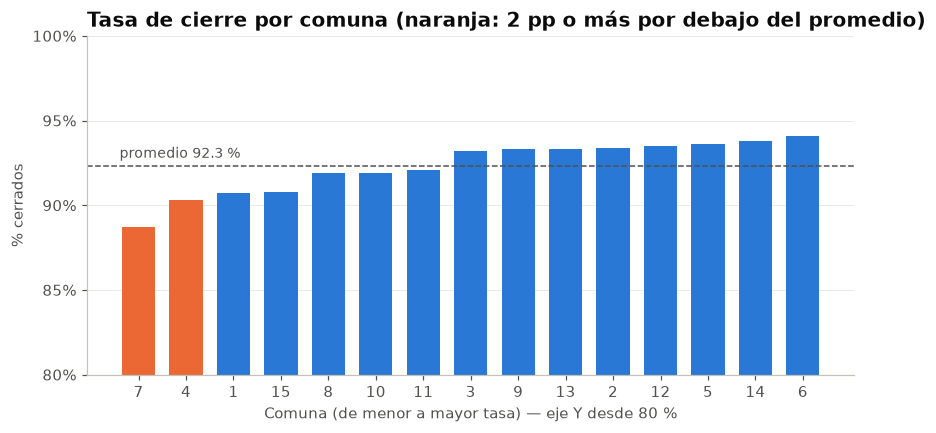

In [13]:
promedio = p4["tasa_cierre_pct"].mean()
fig, ax = plt.subplots(figsize=(9, 4))
colores = [NARANJA if c == "por debajo" else AZUL for c in p4["comparacion"]]
ax.bar(p4["comuna"].astype(str), p4["tasa_cierre_pct"], color=colores, width=0.7)
ax.axhline(promedio, color=TEXTO_2, linewidth=1, linestyle="--")
ax.text(-0.4, promedio + 0.3, f"promedio {promedio:.1f} %", ha="left", va="bottom", color=TEXTO_2, fontsize=9)
ax.set_ylim(80, 100)
ax.set_yticks(range(80, 101, 5))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.set_title("Tasa de cierre por comuna (naranja: 2 pp o más por debajo del promedio)")
ax.set_xlabel("Comuna (de menor a mayor tasa) — eje Y desde 80 %")
ax.set_ylabel("% cerrados")
guardar(fig, "05_tasa_cierre_comuna")
plt.show()

La diferencia entre comunas es chica (unos 5 puntos). Para ver si responde a la mezcla de categorías,
miramos qué tienen abierto las dos comunas por debajo del promedio:

In [14]:
con.sql("""
    SELECT comuna, categoria, count(*) FILTER (WHERE NOT cerrado) AS abiertos,
           round(100 * avg(CASE WHEN cerrado THEN 1 ELSE 0 END), 1) AS tasa_cierre_pct
    FROM reclamos
    WHERE comuna IN (7, 4)
    GROUP BY ALL
    ORDER BY abiertos DESC
    LIMIT 6
""").df()

,comuna,categoria,abiertos,tasa_cierre_pct
0,7,VEREDAS,6084,36.0
1,4,VEREDAS,4896,40.4
2,7,RESOLUCIONES URBANAS,4772,45.7
3,7,ARBOLADO,3422,74.1
4,4,SALUD,2430,73.4
5,4,ARBOLADO,2171,78.0


## 5. Estacionalidad

### P5. ¿Hay patrones por día de la semana o por mes?

In [15]:
consulta("p5a_estacionalidad_dia_semana")

,dia_semana,promedio_diario,dif_vs_dia_promedio_pct
0,Lunes,4278.0,29.7
1,Martes,4077.0,23.6
2,Miércoles,3983.0,20.7
3,Jueves,3939.0,19.4
4,Viernes,3798.0,15.1
5,Sábado,1582.0,-52.1
6,Domingo,1412.0,-57.2


In [16]:
consulta("p5b_estacionalidad_mes")

,mes,reclamos_2024,reclamos_2025,pct_del_bienio
0,1,61906.0,65299.0,5.7
1,2,62605.0,81550.0,6.4
2,3,68843.0,228766.0,13.3
3,4,68164.0,176695.0,10.9
4,5,71497.0,84807.0,7.0
5,6,54527.0,74592.0,5.8
6,7,64099.0,81807.0,6.5
7,8,67281.0,85965.0,6.8
8,9,67225.0,103314.0,7.6
9,10,65913.0,162042.0,10.2


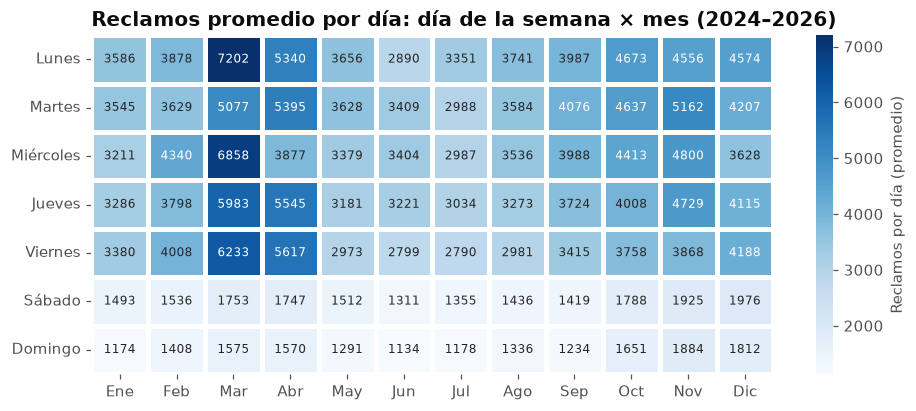

In [17]:
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
# Promedio de reclamos por día, para cada combinación día de la semana x mes (2024–2026)
por_dia = con.sql("""
    SELECT dia_semana_num, mes, avg(n) AS promedio
    FROM (SELECT fecha_ingreso, dia_semana_num, mes, count(*) AS n FROM reclamos GROUP BY ALL)
    GROUP BY ALL
""").df()
matriz = por_dia.pivot(index="dia_semana_num", columns="mes", values="promedio").sort_index()
matriz.index, matriz.columns = dias, meses

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(matriz, cmap="Blues", annot=True, fmt=".0f", annot_kws={"fontsize": 8}, linewidths=2,
            linecolor="white", cbar_kws={"label": "Reclamos por día (promedio)"}, ax=ax)
ax.grid(False)
ax.set_title("Reclamos promedio por día: día de la semana × mes (2024–2026)")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
guardar(fig, "06_heatmap_dia_mes")
plt.show()

## 6. Conclusiones y recomendaciones

Resumen para la jefatura del área (todas las cifras salen de las celdas de arriba):

1. **Dos categorías explican la mitad de la demanda.** HIGIENE (34,5 %) y DENUNCIA VIAL (15,9 %) suman el 50,4 % de
   los 3,36 millones de reclamos. Además, HIGIENE pasó de ~30.500 a ~46.500 reclamos por mes desde octubre de 2025
   (+53 %). *Recomendación:* revisar con el área de higiene urbana si la capacidad operativa acompañó ese aumento,
   porque es el principal motor del volumen total.

2. **VEREDAS es el principal stock pendiente.** Tiene 100 mil reclamos y solo el 44,6 % cerrado: más de 55 mil
   siguen abiertos, más que cualquier otra categoría de reclamos. *Recomendación:* plan específico de reparación
   con meta de cierre y seguimiento mensual.

3. **Las diferencias entre comunas son chicas y tienen causa concreta.** La tasa de cierre va de 88,7 % (Comuna 7)
   a 94,1 % (Comuna 6). Las dos comunas por debajo del promedio (7 y 4) acumulan sus abiertos en VEREDAS (36 % y
   40 % de cierre) y, en la Comuna 7, en RESOLUCIONES URBANAS (46 %). *Recomendación:* priorizar veredas en esas
   dos comunas antes que reforzar la atención en general.

4. **La demanda es de días hábiles.** Un lunes promedio recibe 4.278 reclamos, tres veces más que un domingo
   (1.412). *Recomendación:* dimensionar los equipos de atención y de gestión con más personal de lunes a miércoles.

5. **Hay olas puntuales que distorsionan los promedios.** En marzo y abril de 2025 entraron ~237 mil consultas por
   demoras en expedientes de catastro y obras, y desde octubre de 2025 aparecen ~18 mil reportes automáticos de Boti
   por mes (turnos médicos sin cubrir). *Recomendación:* monitorear el volumen semanal por prestación para detectar
   estas olas a tiempo y separar los reportes automáticos de los reclamos de vecinos.

**Limitaciones:** el dataset no publica fecha de cierre (no se puede medir tiempo de resolución), la hora de 2024–2025
tiene un error de origen y una de cada cuatro filas no tiene comuna. Pedir al área responsable la fecha de cierre
permitiría pasar de "% cerrado" a tiempos de resolución y cumplimiento de plazos.
